In [1]:
# Notebooks live in Notebooks/GRUMish/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
for p in [os.getcwd(), os.path.join(os.getcwd(), "Notebooks", "GRUMish")]:
    if p not in sys.path:
        sys.path.insert(0, p)
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# 01 — The data, and how we measure a preference (2026-11-02, weights revised 2026-11-03)

**GRUMish series** (laptops only, no new runs): 00 README · **01 data and weights** · 02 one requirement ·
03 brand contracts · 04 two and three requirements · 05 what the base model can predict · 06 how many samples.

This notebook sets up the two objects every later notebook uses:
1. **which runs exist** (which model got which contract);
2. **the weights** — how much the model likes each level of each feature, and how a laptop's utility is built from them.

In [2]:
from grumish import *
import matplotlib.pyplot as plt
setup_plots()
FIG = "figs/GRUMish"; os.makedirs(FIG, exist_ok=True)
R = load_all()
print(len(R), "runs (frame `shopping`, complete, 9900 rows each)")

96 runs (frame `shopping`, complete, 9900 rows each)


## 1. Which runs exist

A **contract** is the sentence in the prompt, like *"I prefer 8 GB ram and a 14-inch screen."*. It names 0, 1, 2 or
3 features. Every run = one model × one contract, all 45 laptops, all 990 pairs in both orders, 5 templates.

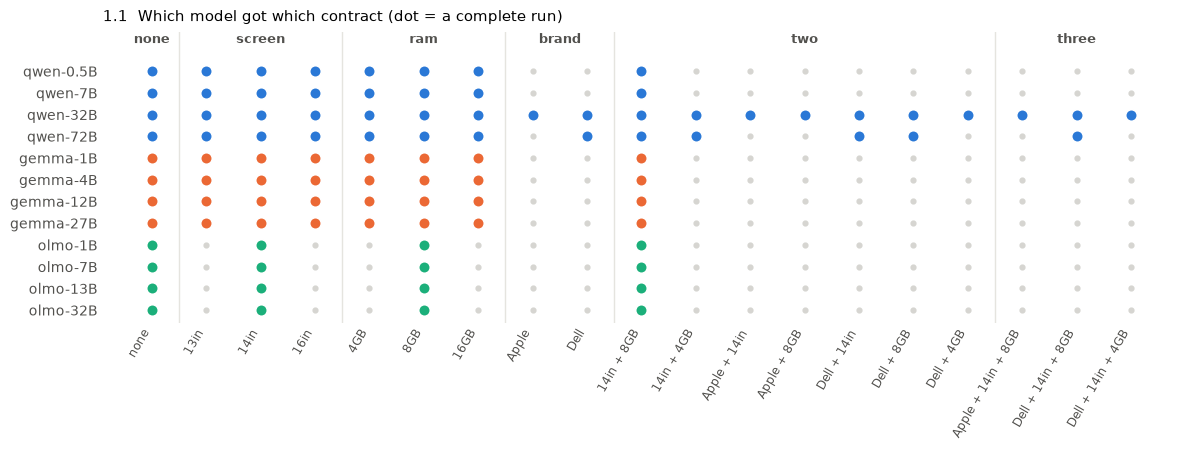

{'none': 12, 'screen': 28, 'ram': 28, 'brand': 3, 'two': 21, 'three': 4}


In [3]:
GROUPS = [("none", ["none"]),
          ("screen", ["screen=13-inch", "screen=14-inch", "screen=16-inch"]),
          ("ram", ["ram=4GB", "ram=8GB", "ram=16GB"]),
          ("brand", ["brand=Apple", "brand=Dell"]),
          ("two", ["ram=8GB+screen=14-inch", "ram=4GB+screen=14-inch", "brand=Apple+screen=14-inch", "brand=Apple+ram=8GB",
                   "brand=Dell+screen=14-inch", "brand=Dell+ram=8GB", "brand=Dell+ram=4GB"]),
          ("three", ["brand=Apple+ram=8GB+screen=14-inch", "brand=Dell+ram=8GB+screen=14-inch", "brand=Dell+ram=4GB+screen=14-inch"])]
CONS = [c for _, cs in GROUPS for c in cs]
fig, ax = plt.subplots(figsize=(12, 4.6))
for j, c in enumerate(CONS):
    for i, m in enumerate(MODELS):
        if (m, c) in R:
            ax.scatter(j, i, s=70, color=FAMC[FAMILY[m]], edgecolor="white", linewidth=1.2, zorder=3)
        else:
            ax.scatter(j, i, s=12, color=LGRAY, zorder=2)
x0 = 0
for g, cs in GROUPS:
    ax.text(x0 + (len(cs) - 1) / 2, -1.3, g, ha="center", fontsize=9.5, fontweight="bold", color=INK2)
    if x0: ax.axvline(x0 - 0.5, color=GRID, lw=1)
    x0 += len(cs)
ax.set_xticks(range(len(CONS)), [short(c) for c in CONS], rotation=60, ha="right", fontsize=8.5)
ax.set_yticks(range(len(MODELS)), MODELS); ax.set_ylim(len(MODELS) - 0.4, -1.8)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title("1.1  Which model got which contract (dot = a complete run)", loc="left", pad=8)
fig.tight_layout(); fig.savefig(f"{FIG}/01_1_coverage.png", dpi=150); plt.show()
print({g: sum((m, c) in R for c in cs for m in MODELS) for g, cs in GROUPS})

- **96 complete runs.** The 8 qwen and gemma models have **all 6 one-requirement spec contracts** (13/14/16-inch,
  4/8/16GB). OLMo has only `14-inch` and `8GB`.
- **Brand contracts and almost all two- and three-requirement contracts exist only for qwen-32B (19 contracts) and
  qwen-72B (13).** Only 4 three-requirement runs exist.
- So: questions about **levels** can use 7 models (qwen-0.5B is noise); questions about **brand and compounds** are
  mostly about qwen-32B and qwen-72B. Every result in notebooks 03–04 carries that limit.

## 2. How we measure: the position-corrected margin D, and the weights

**D.** For two laptops x and y the model gives a margin m(x, y) = log-prob("1") − log-prob("2") when x is option 1.
We ask both orders and average: **D(x, y) = (m(x, y) − m(y, x)) / 2**. The pull toward option 1 or 2 (positional
bias) cancels, and so does the PMI constant of the old runs. Nothing below needs γ.

**Weights.** We want one number per level ("how much does the model like 16 GB, 8 GB, 4 GB?"), and a laptop's utility
= the sum of its three weights. Two ways to get them:
- **all-pairs** (the `FeatureBT` shape): least squares of *D(x, y) ≈ u(x) − u(y)* with *u = w(brand) + w(screen) +
  w(ram)*, on **all 990 pairs**.
- **ceteris paribus (CP)**: each feature **only on pairs that differ in that feature alone**. Brand from
  "Apple 14in 8GB vs Dell 14in 8GB" (90 pairs), screen from pairs with the same brand and RAM (45), RAM likewise (45).

Weights are centred inside each feature (0 = the average level).

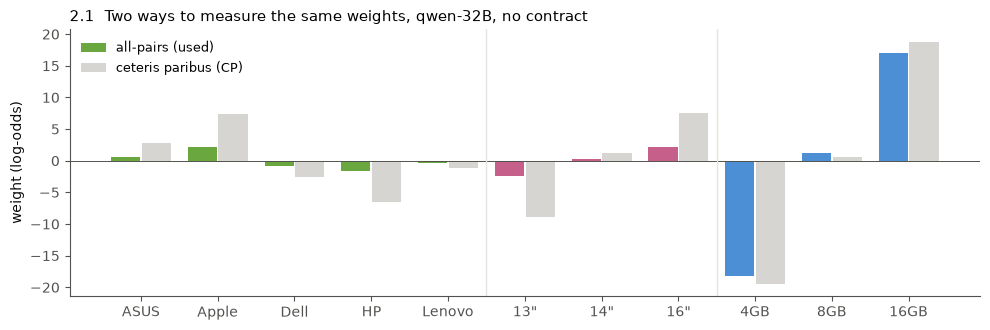

CP range / all-pairs range, no contract:
        qwen-7B  qwen-32B  qwen-72B  gemma-1B  gemma-4B  gemma-12B  gemma-27B  olmo-1B  olmo-7B  olmo-13B  olmo-32B
brand       5.6       3.6       2.8       2.3       3.4        3.2        4.1      1.2      1.4       0.9       1.5
screen      3.4       3.5       2.7       3.0       3.8        3.2        3.4      2.9      2.4       2.8       2.1
ram         1.1       1.1       1.2       1.1       0.9        1.0        1.0      1.4      1.2       1.1       1.2


In [4]:
m = "qwen-32B"
fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(LV)); r = R[(m, "none")]
ax.bar(x - 0.2, r.w.values, 0.38, color=[FEATC[f] for f, _ in LV], label="all-pairs (used)")
ax.bar(x + 0.2, r.wcp.values, 0.38, color=LGRAY, label="ceteris paribus (CP)")
ax.axhline(0, color=INK2, lw=0.7)
for b in (4.5, 7.5): ax.axvline(b, color=GRID, lw=1)
ax.set_xticks(x, [l.replace("-inch", '"') for _, l in LV]); ax.set_ylabel("weight (log-odds)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title(f"2.1  Two ways to measure the same weights, {m}, no contract", loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/01_2_cp_vs_allpairs.png", dpi=150); plt.show()
rng = lambda w, f: w[f].max() - w[f].min()
ratio = pd.DataFrame({m: {f: rng(R[(m, "none")].wcp, f) / rng(R[(m, "none")].w, f) for f in FEATS} for m in REAL})
print("CP range / all-pairs range, no contract:"); print(ratio.round(1).to_string())

- **RAM is measured the same either way** (CP / all-pairs = 0.9–1.4): RAM decides most pairs anyway.
- **Brand and screen come out 2–6× bigger with CP** in qwen and gemma (brand 2.3–5.6×, screen 2.1–3.8×). In OLMo,
  whose brand taste is tiny, the two agree for brand (0.9–1.5).
- Why: the models are lexicographic. When RAM differs, RAM decides and brand hardly matters. CP measures brand only
  where it is the only difference; all-pairs measures how much brand matters **over all pairs** — which is little.

**Which one predicts the model's choices better?** For every run, use the run's own weights, sum them per laptop, and
score against the run's D: **pair accuracy** (share of the 990 pairs with the same winner) and **pair R²** (how well
u(x) − u(y) matches D in size, not only in sign). A third line: one free utility per laptop (45 numbers, no feature
structure) — the best any utility model can do.

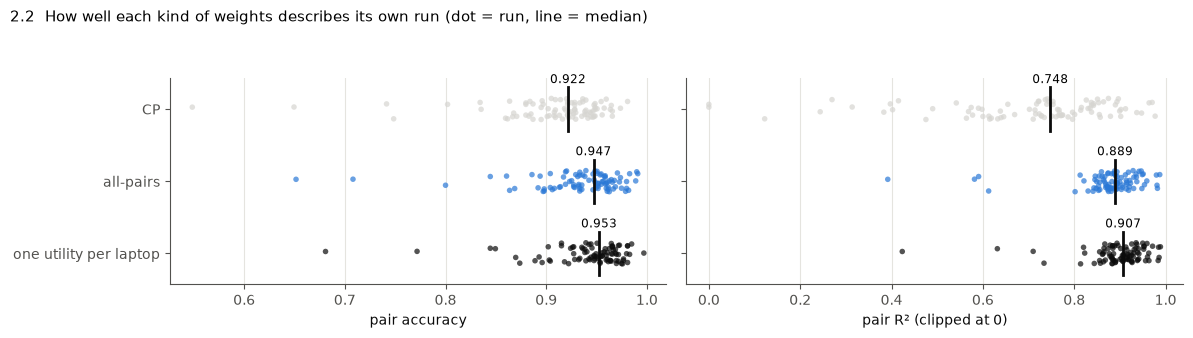

                          acc     R2
kind                                
CP                      0.922  0.748
all-pairs               0.947  0.889
one utility per laptop  0.953  0.907
runs where all-pairs beats CP in accuracy: 69 of 88


In [5]:
rows = []
for (m, c), r in R.items():
    if m == "qwen-0.5B": continue
    for k, u in [("CP", additive_utility(r.wcp)), ("all-pairs", additive_utility(r.w)), ("one utility per laptop", r.u)]:
        rows.append(dict(model=m, c=c, kind=k, acc=pair_accuracy(u, r.D), R2=pair_r2(u, r.D)))
CMP = pd.DataFrame(rows)
KINDS = ["CP", "all-pairs", "one utility per laptop"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, col, lo in [(axes[0], "acc", 0.5), (axes[1], "R2", 0.0)]:
    for i, (k, c_) in enumerate(zip(KINDS, [LGRAY, BLUE, INK])):
        v = CMP[CMP.kind == k][col].clip(lower=lo)
        ax.scatter(v, i + np.random.default_rng(1).uniform(-0.15, 0.15, len(v)), s=16, color=c_, alpha=0.7, edgecolor="none")
        ax.plot([v.median()] * 2, [i - 0.3, i + 0.3], color=INK, lw=2)
        ax.text(v.median(), i - 0.36, f"{v.median():.3f}", ha="center", fontsize=8.5)
    ax.set_yticks(range(3), KINDS); ax.invert_yaxis(); ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_xlabel("pair accuracy" if col == "acc" else "pair R² (clipped at 0)")
axes[1].set_yticklabels([])
fig.suptitle("2.2  How well each kind of weights describes its own run (dot = run, line = median)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92)); fig.savefig(f"{FIG}/01_2b_which_weights.png", dpi=150); plt.show()
print(CMP.groupby("kind")[["acc", "R2"]].median().loc[KINDS].round(3).to_string())
print("runs where all-pairs beats CP in accuracy:", (CMP[CMP.kind == "all-pairs"].acc.values > CMP[CMP.kind == "CP"].acc.values).sum(), "of", len(CMP) // 3)

- **all-pairs describes the run better than CP**: median pair accuracy **0.947 vs 0.922**, pair R² **0.89 vs 0.75**;
  better in 69 of 88 runs.
- all-pairs is almost as good as one free utility per laptop (0.953, R² 0.91): the feature structure costs very little.
- CP is worse because its brand weight is the brand effect **in a tie**. Summed into every pair, it also acts in the
  pairs where RAM differs, where it should be ~0. A big RAM weight next to a small brand weight is how a sum mimics
  a lexicographic order.
- **Decision (2026-11-03): all-pairs is the weight used everywhere in this series** (`Run.w`). CP is kept as
  `Run.wcp`, only to describe the taste "when all else is equal". (Before 11-03 the series used CP.)

## 3. The weights of every model with no contract

This is **a** in the GRUM: the model's own taste, the starting point that every contract changes.
Error bar = min–max over the 5 templates (each template is a full design on its own).

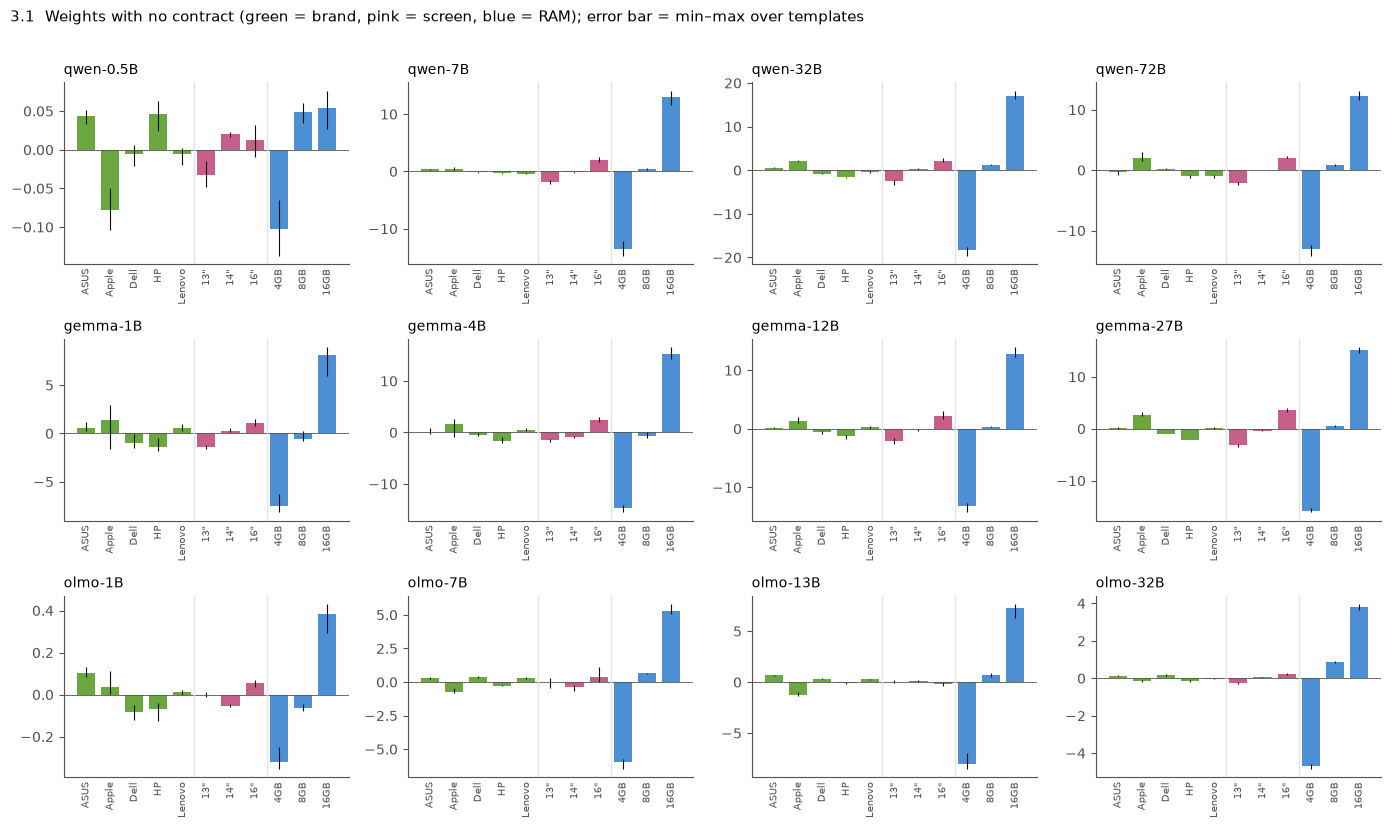

        qwen-0.5B  qwen-7B  qwen-32B  qwen-72B  gemma-1B  gemma-4B  gemma-12B  gemma-27B  olmo-1B  olmo-7B  olmo-13B  olmo-32B
brand         0.1      0.9       3.8       2.8       2.8       3.4        2.5        4.9      0.2      1.1       1.9       0.3
screen        0.1      3.9       4.7       4.3       2.5       3.9        4.3        6.8      0.1      0.8       0.3       0.5
ram           0.2     26.5      35.2      25.4      15.6      30.0       25.9       30.9      0.7     11.3      15.2       8.5


In [6]:
fig, axes = plt.subplots(3, 4, figsize=(14, 8.4))
for ax, m in zip(axes.flat, MODELS):
    r = R[(m, "none")]; mu = r.w.values; x = np.arange(len(LV))
    ax.bar(x, mu, 0.75, color=[FEATC[f] for f, _ in LV])
    ax.errorbar(x, mu, yerr=np.vstack([mu - r.w_t.min(axis=1).values, r.w_t.max(axis=1).values - mu]), fmt="none", ecolor=INK, elinewidth=0.8)
    ax.axhline(0, color=INK2, lw=0.6)
    for b in (4.5, 7.5): ax.axvline(b, color=GRID, lw=1)
    ax.set_xticks(x, [l.replace("-inch", '"') for _, l in LV], rotation=90, fontsize=7.5); ax.tick_params(axis="x", length=0)
    ax.set_title(m, loc="left", fontsize=10)
fig.suptitle("3.1  Weights with no contract (green = brand, pink = screen, blue = RAM); error bar = min–max over templates", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.97)); fig.savefig(f"{FIG}/01_3_base_weights.png", dpi=150); plt.show()
W0 = pd.DataFrame({m: R[(m, "none")].w for m in MODELS})
print(pd.DataFrame({f: W0.loc[f].max() - W0.loc[f].min() for f in FEATS}).T.round(1).to_string())

- **RAM is the biggest feature in every model by far**: range 9–35 log-odds, vs brand 0.3–4.9 and screen 0.1–6.8.
  With all-pairs weights this is what makes the sum act lexicographically.
- **Apple is the top brand in all qwen and gemma models except qwen-0.5B** (+0.5 … +2.7), not in OLMo; HP is at the
  bottom. 16-inch is the favourite screen (not in olmo-13B), 16GB the favourite RAM everywhere.
- **The template error bars are small** next to the weights: the 5 templates agree on the taste.
- qwen-0.5B and olmo-1B have a tiny scale (≤ 1 log-odds): treat them as noise floors.

## 4. The ceiling of every prediction: the oracle

Every GRUM below predicts **feature weights**, and a laptop's utility = the sum of its 3 weights. So even a perfect
GRUM can only be as good as the run's **own** all-pairs weights. Later notebooks call this the **oracle**: the same
numbers as the middle line of 2.2, per model.

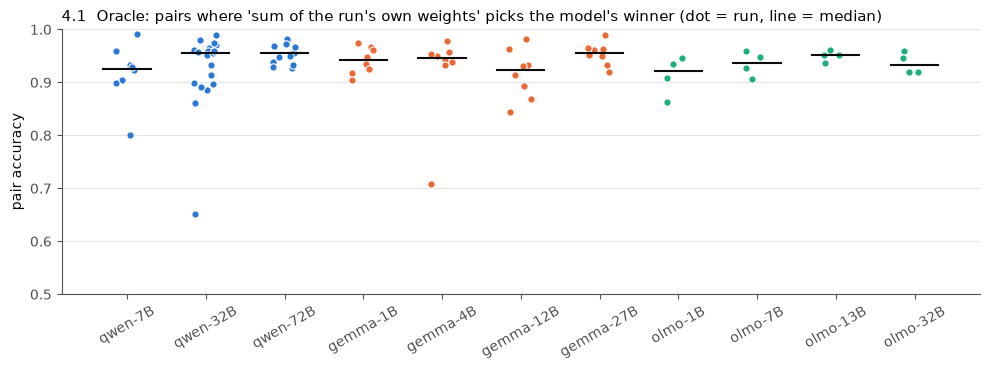

             min  median    max
model                          
qwen-7B    0.800   0.926  0.991
qwen-32B   0.652   0.955  0.990
qwen-72B   0.927   0.955  0.982
gemma-1B   0.904   0.942  0.974
gemma-4B   0.708   0.946  0.979
gemma-12B  0.844   0.923  0.983
gemma-27B  0.919   0.956  0.989
olmo-1B    0.864   0.922  0.946
olmo-7B    0.906   0.937  0.959
olmo-13B   0.936   0.952  0.962
olmo-32B   0.919   0.933  0.960
all runs: {'count': 88.0, 'mean': 0.933, 'std': 0.052, 'min': 0.652, '25%': 0.92, '50%': 0.947, '75%': 0.961, 'max': 0.991}
         model                   c    acc     R2
22    qwen-32B             ram=4GB  0.652  0.392
52    gemma-4B             ram=4GB  0.708  0.582
151    qwen-7B             ram=8GB  0.800  0.981
64   gemma-12B             ram=4GB  0.844  0.591
130   qwen-32B  brand=Dell+ram=4GB  0.861  0.855
232    olmo-1B             ram=8GB  0.864  0.853


In [7]:
ACC = CMP[CMP.kind == "all-pairs"]
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, m in enumerate(REAL):
    s = ACC[ACC.model == m]
    ax.scatter(np.full(len(s), i) + np.random.default_rng(0).uniform(-0.15, 0.15, len(s)), s.acc, s=28,
               color=FAMC[FAMILY[m]], edgecolor="white", linewidth=0.8, zorder=3)
    ax.plot([i - 0.3, i + 0.3], [s.acc.median()] * 2, color=INK, lw=1.5, zorder=4)
ax.set_xticks(range(len(REAL)), REAL, rotation=30); ax.set_ylabel("pair accuracy")
ax.set_ylim(0.5, 1.0); ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_title("4.1  Oracle: pairs where 'sum of the run's own weights' picks the model's winner (dot = run, line = median)", loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/01_4_oracle.png", dpi=150); plt.show()
print(ACC.groupby("model").acc.agg(["min", "median", "max"]).loc[REAL].round(3).to_string())
print("all runs:", ACC.acc.describe().round(3).to_dict())
print(ACC.sort_values("acc").head(6)[["model", "c", "acc", "R2"]].round(3).to_string())

- **The ceiling is 0.947 pair accuracy** (median over 88 runs; 0.92–0.96 per model). Later notebooks compare every
  prediction with it.
- **The hard runs are `ram=4GB`**: qwen-32B 0.65, gemma-4B 0.71, gemma-12B 0.84. There the model is torn between the
  request and its strong taste, and no simple sum describes it.